# 02.2 · Linear regression by hand: the best straight line

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/02-linear-regression-by-hand/lesson.ipynb)

Read the [README](README.md) first and do the by-hand table on paper. This notebook repeats it in code three ways (plain Python, NumPy, scikit-learn), and every number should match what you wrote down.

Then we apply the method to 20 customers, and to the real data.

## 1. The five customers

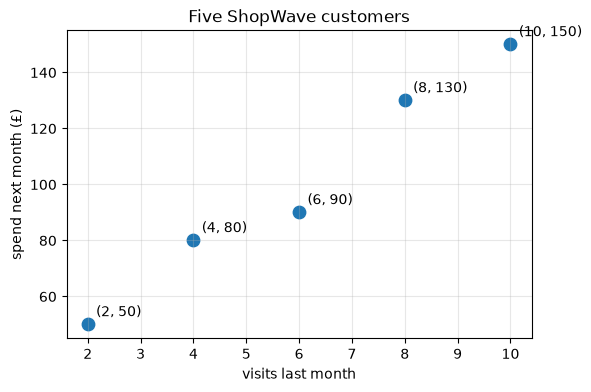

In [1]:
x = [2, 4, 6, 8, 10]          # visits last month
y = [50, 80, 90, 130, 150]    # spend next month, £

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=80, color="tab:blue")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi}, {yi})", (xi, yi), textcoords="offset points", xytext=(6, 6))
plt.xlabel("visits last month"); plt.ylabel("spend next month (£)")
plt.title("Five ShopWave customers"); plt.grid(alpha=.3)
plt.show()

## 2. Plain Python: the by-hand table, typed in

Follow the README steps. Compare each printed number with your paper.

In [2]:
n = len(x)
x_mean = sum(x) / n
y_mean = sum(y) / n
print("Step 1  x_mean =", x_mean, "  y_mean =", y_mean)

numerator = 0
denominator = 0
print("\nStep 2  deviations")
print(f"{'x':>3} {'y':>4} {'x-x̄':>5} {'y-ȳ':>5} {'product':>8} {'(x-x̄)²':>8}")
for xi, yi in zip(x, y):
    dx, dy = xi - x_mean, yi - y_mean
    numerator += dx * dy
    denominator += dx * dx
    print(f"{xi:>3} {yi:>4} {dx:>5.0f} {dy:>5.0f} {dx*dy + 0.0:>8.0f} {dx*dx:>8.0f}")
print(f"{'':>19} {'sum':>5} {numerator:>8.0f} {denominator:>8.0f}")

m = numerator / denominator
c = y_mean - m * x_mean
print("\nStep 3  m =", m)
print("Step 4  c =", c)
print(f"Step 5  model:  spend = {m} × visits + {c}")
print("Step 6  prediction for 7 visits:", m * 7 + c)

Step 1  x_mean = 6.0   y_mean = 100.0

Step 2  deviations
  x    y  x-x̄   y-ȳ  product  (x-x̄)²
  2   50    -4   -50      200       16
  4   80    -2   -20       40        4
  6   90     0   -10        0        0
  8  130     2    30       60        4
 10  150     4    50      200       16
                      sum      500       40

Step 3  m = 12.5
Step 4  c = 25.0
Step 5  model:  spend = 12.5 × visits + 25.0
Step 6  prediction for 7 visits: 112.5


## 3. Residuals: how good is the line?

A **residual** is `actual − predicted` for one row. The line is "best" because the sum of the *squared* residuals is as small as any straight line can make it.

In [3]:
print(f"{'x':>3} {'y':>4} {'ŷ':>6} {'resid':>6} {'resid²':>7}")
sse = 0
for xi, yi in zip(x, y):
    y_hat = m * xi + c
    r = yi - y_hat
    sse += r * r
    print(f"{xi:>3} {yi:>4} {y_hat:>6.1f} {r:>6.1f} {r*r:>7.1f}")
print(f"{'':>15} {'sum':>6} {sse:>7.1f}")

  x    y      ŷ  resid  resid²
  2   50   50.0    0.0     0.0
  4   80   75.0    5.0    25.0
  6   90  100.0  -10.0   100.0
  8  130  125.0    5.0    25.0
 10  150  150.0    0.0     0.0
                   sum   150.0


### Try to beat it

Change `m_try` and `c_try` below. Whatever you pick, the sum of squared residuals will be **≥ 150**. That is the meaning of least squares.

In [4]:
m_try, c_try = 12.0, 28.0      # <-- edit me

sse_try = sum((yi - (m_try * xi + c_try)) ** 2 for xi, yi in zip(x, y))
print(f"m={m_try}, c={c_try}  →  sum of squared residuals = {sse_try:.1f}   (least squares: {sse:.1f})")

m=12.0, c=28.0  →  sum of squared residuals = 160.0   (least squares: 150.0)


## 4. NumPy: the same formula without loops

NumPy does arithmetic on whole arrays at once. Each line below is one column of your table.

In [5]:
import numpy as np
x_arr = np.array(x, dtype=float)
y_arr = np.array(y, dtype=float)

dx = x_arr - x_arr.mean()          # column: x - x̄
dy = y_arr - y_arr.mean()          # column: y - ȳ
m_np = (dx * dy).sum() / (dx ** 2).sum()
c_np = y_arr.mean() - m_np * x_arr.mean()
print("m =", m_np, " c =", c_np)

m = 12.5  c = 25.0


## 5. scikit-learn: what you will use from now on

`LinearRegression` runs exactly this formula. Two things to know:

- `X` must be **2-D**: one row per example, one column per feature. With a single feature that means shape `(5, 1)`, hence `reshape(-1, 1)`.
- After `fit`, `coef_` holds the slope(s) and `intercept_` the intercept.

In [6]:
from sklearn.linear_model import LinearRegression

X = x_arr.reshape(-1, 1)          # shape (5, 1): 5 customers, 1 feature
model = LinearRegression()
model.fit(X, y_arr)

print("m (coef_)      =", model.coef_[0])
print("c (intercept_) =", model.intercept_)
print("predict 7 visits =", model.predict([[7]])[0])

m (coef_)      = 12.5
c (intercept_) = 25.0
predict 7 visits = 112.5


Three methods, one answer. Let us draw the line.

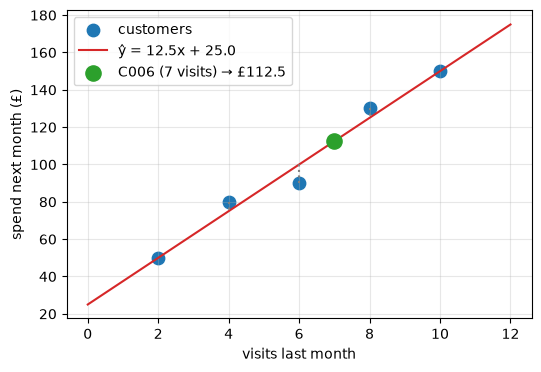

In [7]:
xs = np.linspace(0, 12, 50)
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=80, label="customers")
plt.plot(xs, m * xs + c, color="tab:red", label=f"ŷ = {m}x + {c}")
plt.scatter([7], [m * 7 + c], color="tab:green", s=120, zorder=5, label="C006 (7 visits) → £112.5")
for xi, yi in zip(x, y):                                    # residual sticks
    plt.plot([xi, xi], [yi, m * xi + c], color="gray", linestyle=":")
plt.xlabel("visits last month"); plt.ylabel("spend next month (£)")
plt.legend(); plt.grid(alpha=.3); plt.show()

The dotted sticks are the residuals. Least squares picks the line that makes the sum of their *squared* lengths smallest.

## 6. Twenty customers

Now the small ShopWave table. Numbers are no longer tidy, and that is the point: the formula does not care.

In [8]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
cust = pd.read_csv(data_path("shopwave_customers_small.csv"))
cust.head()

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1


In [9]:
X20 = cust[["visits_last_month"]]          # a DataFrame with one column is already 2-D
y20 = cust["spend_next_month"]

model20 = LinearRegression().fit(X20, y20)
m20, c20 = model20.coef_[0], model20.intercept_
print(f"spend ≈ {m20:.2f} × visits + {c20:.2f}")
print(f"Each extra visit is worth about £{m20:.2f} of next-month spend.")

spend ≈ 17.17 × visits + 19.61
Each extra visit is worth about £17.17 of next-month spend.


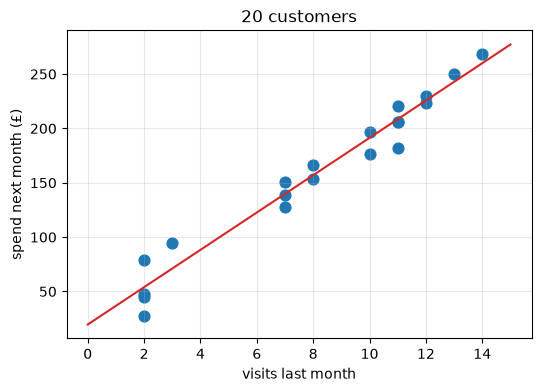

,customer_id,visits_last_month,spend_next_month,predicted,residual
0,C001,2,27.6,54.0,-26.3
14,C015,11,182.2,208.5,-26.3
2,C003,10,176.2,191.3,-15.1
3,C004,7,127.6,139.8,-12.2
9,C010,2,45.0,54.0,-8.9
6,C007,2,47.3,54.0,-6.6
10,C011,8,153.7,157.0,-3.3
13,C014,11,206.0,208.5,-2.5
12,C013,11,206.3,208.5,-2.2
18,C019,12,223.7,225.7,-2.0


In [10]:
cust["predicted"] = model20.predict(X20)
cust["residual"] = cust["spend_next_month"] - cust["predicted"]

plt.figure(figsize=(6, 4))
plt.scatter(cust["visits_last_month"], cust["spend_next_month"], s=60)
xs = np.linspace(0, 15, 50)
plt.plot(xs, m20 * xs + c20, color="tab:red")
plt.xlabel("visits last month"); plt.ylabel("spend next month (£)")
plt.title("20 customers"); plt.grid(alpha=.3); plt.show()

cust.sort_values("residual")[["customer_id", "visits_last_month", "spend_next_month", "predicted", "residual"]].round(1)

Look at the biggest positive and negative residuals. Those customers spent much more (or less) than visits alone would suggest. Something else matters: lesson 02.5 adds the other columns.

## 7. The real data

The Online Retail II dataset has no "visits", but it has orders. We ask the same question at scale: does the number of orders a customer placed in 2010 predict what they spent in the first quarter of 2011?

(Data handling here uses Pandas you learn in Module 01. Skim it; the regression part at the end is the same two lines.)

In [11]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
raw = raw.dropna(subset=["Customer ID"])
raw = raw[(raw["Quantity"] > 0) & (raw["Price"] > 0)]
raw["amount"] = raw["Quantity"] * raw["Price"]

past = raw[raw["InvoiceDate"] < "2011-09-01"]
future = raw[(raw["InvoiceDate"] >= "2011-09-01") & (raw["InvoiceDate"] < "2011-12-01")]

orders_past = past.groupby("Customer ID")["Invoice"].nunique().rename("orders")
spend_future = future.groupby("Customer ID")["amount"].sum().rename("spend")
table = pd.concat([orders_past, spend_future], axis=1).fillna(0)
table = table[table["orders"] > 0]
print(f"{len(table):,} customers")
table.describe().round(1)

3,317 customers


,orders,spend
count,3317.0,3317.0
mean,3.4,778.3
std,5.6,3929.1
min,1.0,0.0
25%,1.0,0.0
50%,2.0,171.4
75%,4.0,690.1
max,127.0,117634.5


spend_next_quarter ≈ 316.5 × past_orders + -310.7


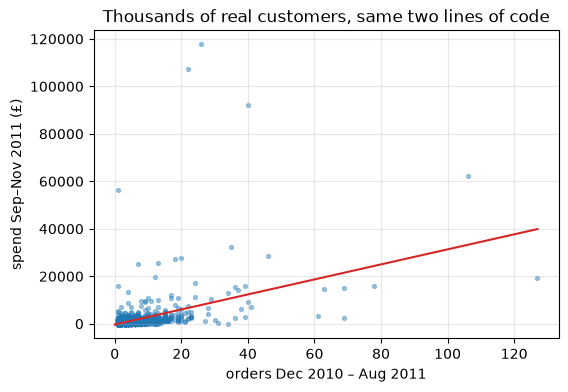

In [12]:
big = LinearRegression().fit(table[["orders"]], table["spend"])
print(f"spend_next_quarter ≈ {big.coef_[0]:.1f} × past_orders + {big.intercept_:.1f}")

plt.figure(figsize=(6, 4))
plt.scatter(table["orders"], table["spend"], s=8, alpha=.4)
xs = np.linspace(0, table["orders"].max(), 50)
plt.plot(xs, big.coef_[0] * xs + big.intercept_, color="tab:red")
plt.xlabel("orders Dec 2010 – Aug 2011"); plt.ylabel("spend Sep–Nov 2011 (£)")
plt.title("Thousands of real customers, same two lines of code")
plt.grid(alpha=.3); plt.show()

Notice the cloud: most customers sit near the bottom-left and a few outliers stretch far up and right. Those few points pull the line (section 8 of the README). Handling that honestly is what Modules 01 and 04 teach.

## Quiz answers

1. $m$ is the extra spend, in pounds, for each additional visit.
2. Residuals above and below the line would cancel if simply added. Squaring makes them all positive and makes large misses count more.
3. The point $(\bar{x}, \bar{y})$: the mean of $x$ and the mean of $y$.
4. `coef_` is $m$ (one value per feature); `intercept_` is $c$.
5. Any of: spend depends on more than visits; the line was fitted on five points; the relationship may not be straight; C006 may be an unusual customer; correlation is not causation.

**Next:** [02.3 Measuring error](../03-measuring-error/)